# GND Gender Classifier Training

This notebook trains a gender classifier using the complete GND (Gemeinsame Normdatei) person authority dataset from the German National Library (DNB).

**Data Source:** https://data.dnb.de/GND/authorities-gnd-person_dnbmarc.mrc.xml.gz

**Goal:** Extract person records with name, birth date, and gender information to train a robust gender classification model.

In [1]:
!pip install lxml polars scikit-learn xgboost matplotlib seaborn tqdm requests numpy gender-guesser cupy-cuda12x

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 48.6 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 810.4/810.4 kB 85.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 80.1 MB/s eta 0:00:00:00:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.7/131.7 MB 17.5 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 81.7 MB/s eta 0:00:00:00:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 kB 69.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.1/135.1 MB 15.9 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.8/45.8 MB 40.3 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 46.0 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 309.1/309.1 kB 68.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 355.2/355.2 kB 67.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## 1. Download and Extract GND Data

Download the complete GND person authority dataset in MARC 21 XML format.

In [2]:
import requests
import gzip
import shutil
import os
from pathlib import Path
from lxml import etree
from tqdm import tqdm
import polars as pl
import numpy as np

# Setup paths
data_dir = Path('../data/raw/GND')
data_dir.mkdir(parents=True, exist_ok=True)

# URLs
GND_URL = 'https://data.dnb.de/GND/authorities-gnd-person_dnbmarc.mrc.xml.gz'
gz_file = data_dir / 'authorities-gnd-person_dnbmarc.mrc.xml.gz'
xml_file = data_dir / 'authorities-gnd-person_dnbmarc.mrc.xml'

print(f"Data directory: {data_dir}")
print(f"Download URL: {GND_URL}")

Data directory: ../data/raw/GND
Download URL: https://data.dnb.de/GND/authorities-gnd-person_dnbmarc.mrc.xml.gz


In [3]:
# Download the GND dataset (warning: this is a large file, ~2-3 GB compressed)
if not gz_file.exists():
    print(f"Downloading GND dataset from {GND_URL}...")
    print("This may take several minutes (file is ~2-3 GB)...")

    response = requests.get(GND_URL, stream=True)
    response.raise_for_status()

    # Get total file size
    total_size = int(response.headers.get('content-length', 0))
    block_size = 8192

    # Download with progress bar
    with open(gz_file, 'wb') as f:
        with tqdm(total=total_size, unit='iB', unit_scale=True, desc='Downloading') as pbar:
            for chunk in response.iter_content(chunk_size=block_size):
                if chunk:
                    f.write(chunk)
                    pbar.update(len(chunk))

    print(f"✓ Download complete: {gz_file}")
else:
    print(f"✓ File already downloaded: {gz_file}")

# Check file size
file_size_mb = gz_file.stat().st_size / (1024 * 1024)
print(f"  Compressed file size: {file_size_mb:.2f} MB")

This may take several minutes (file is ~2-3 GB)...


Downloading: 100%|██████████| 1.64G/1.64G [08:15<00:00, 3.31MiB/s]

✓ Download complete: ../data/raw/GND/authorities-gnd-person_dnbmarc.mrc.xml.gz
  Compressed file size: 1563.51 MB


In [4]:
# Extract the gzipped file
if not xml_file.exists():
    print(f"Extracting {gz_file.name}...")
    print("This may take several minutes...")

    with gzip.open(gz_file, 'rb') as f_in:
        with open(xml_file, 'wb') as f_out:
            # Extract in chunks with progress
            chunk_size = 1024 * 1024  # 1MB chunks
            while True:
                chunk = f_in.read(chunk_size)
                if not chunk:
                    break
                f_out.write(chunk)

    print(f"✓ Extraction complete: {xml_file}")
else:
    print(f"✓ File already extracted: {xml_file}")

# Check extracted file size
xml_size_gb = xml_file.stat().st_size / (1024 * 1024 * 1024)
print(f"  Extracted file size: {xml_size_gb:.2f} GB")

Extracting authorities-gnd-person_dnbmarc.mrc.xml.gz...
This may take several minutes...


✓ Extraction complete: ../data/raw/GND/authorities-gnd-person_dnbmarc.mrc.xml
  Extracted file size: 24.71 GB


## 2. Parse MARC 21 XML Records

Parse the MARC 21 XML file to extract individual person records. The file uses the MARC21 namespace.

In [5]:
# MARC21 XML namespace
MARC_NS = {'marc': 'http://www.loc.gov/MARC21/slim'}

# Test parse - read first few records to understand structure
print("Testing XML structure with first few records...")
context = etree.iterparse(str(xml_file), events=('end',), tag='{http://www.loc.gov/MARC21/slim}record')
record_count = 0

for event, elem in context:
    record_count += 1

    if record_count <= 3:  # Show first 3 records
        print(f"\n{'='*60}")
        print(f"Record {record_count}:")
        print(f"{'='*60}")

        # Show all datafields
        for datafield in elem.xpath('.//marc:datafield', namespaces=MARC_NS):
            tag = datafield.get('tag')
            ind1 = datafield.get('ind1', ' ')
            ind2 = datafield.get('ind2', ' ')

            subfields = []
            for subfield in datafield.xpath('marc:subfield', namespaces=MARC_NS):
                code = subfield.get('code')
                value = subfield.text
                subfields.append(f"${code}: {value}")

            if subfields:
                print(f"  {tag} (ind1='{ind1}', ind2='{ind2}'): {', '.join(subfields)}")

    # Clear element to save memory
    elem.clear()
    while elem.getprevious() is not None:
        del elem.getparent()[0]

    if record_count >= 10:  # Stop after checking structure
        break

del context
print(f"\n✓ XML structure test complete. Total records checked: {record_count}")

Testing XML structure with first few records...

Record 1:
  024 (ind1='7', ind2=' '): $a: 16126667-8, $0: http://d-nb.info/gnd/16126667-8, $2: gnd
  035 (ind1=' ', ind2=' '): $a: (DE-101)051224666
  035 (ind1=' ', ind2=' '): $a: (DE-588)16126667-8
  035 (ind1=' ', ind2=' '): $z: (DE-588b)16126667-8, $9: v:zg
  040 (ind1=' ', ind2=' '): $a: DE-12, $c: DE-12, $9: r:DE-12, $b: ger, $d: 1841
  042 (ind1=' ', ind2=' '): $a: gnd6
  043 (ind1=' ', ind2=' '): $c: ZZ
  075 (ind1=' ', ind2=' '): $b: p, $2: gndgen
  075 (ind1=' ', ind2=' '): $b: piz, $2: gndspec
  079 (ind1=' ', ind2=' '): $a: g, $q: f
  100 (ind1='0', ind2=' '): $a: Paulus, $g: a Sancto Bartholomaeo
  377 (ind1=' ', ind2='7'): $a: lat, $2: iso639-2b
  913 (ind1=' ', ind2=' '): $S: gkd, $i: a, $a: Paulus <a Sancto Bartholomaeo>, $0: (DE-588b)16126667-8

Record 2:
  024 (ind1='7', ind2=' '): $a: 100000193, $0: http://d-nb.info/gnd/100000193, $2: gnd
  035 (ind1=' ', ind2=' '): $a: (DE-101)100000193
  035 (ind1=' ', ind2=' '): $a:

## 3. Extract Relevant Fields

Extract the key MARC21 fields we need:
- **100$a**: Personal name (main entry)
- **375$a**: Gender
- **548$a**: Date of birth and death (with relation type indicators)
- **400$a**: Alternative name forms (if available)

In [6]:
def extract_person_data(record):
    """Extract relevant person data from a MARC21 record."""
    person_data = {
        'name': None,
        'forename': None,
        'surname': None,
        'birth_date': None,
        'death_date': None,
        'gender': None,
        'alt_names': []
    }

    # Extract fields using XPath
    for datafield in record.xpath('.//marc:datafield', namespaces=MARC_NS):
        tag = datafield.get('tag')

        # 100 = Personal name (main entry)
        if tag == '100':
            for subfield in datafield.xpath('marc:subfield', namespaces=MARC_NS):
                code = subfield.get('code')
                if code == 'a':  # Personal name
                    full_name = subfield.text
                    person_data['name'] = full_name

                    # Try to split into surname, forename
                    if ',' in full_name:
                        parts = full_name.split(',', 1)
                        person_data['surname'] = parts[0].strip()
                        person_data['forename'] = parts[1].strip() if len(parts) > 1 else None
                elif code == 'd' and subfield.text:
                    # 100 $d contains birth/death dates, e.g. "1776-1854" or "1776-"
                    date_str = subfield.text.strip().rstrip('.')
                    if '-' in date_str:
                        parts = date_str.split('-', 1)
                        birth = parts[0].strip()
                        death = parts[1].strip() if len(parts) > 1 else None
                        if birth:
                            person_data['birth_date'] = birth
                        if death:
                            person_data['death_date'] = death
                    elif date_str:
                        person_data['birth_date'] = date_str

        # 375 = Gender
        elif tag == '375':
            for subfield in datafield.xpath('marc:subfield', namespaces=MARC_NS):
                code = subfield.get('code')
                if code == 'a':  # Gender
                    gender_value = subfield.text
                    if gender_value:
                        # Normalize gender values
                        gender_lower = gender_value.lower()
                        if 'männlich' in gender_lower or 'male' in gender_lower:
                            person_data['gender'] = 'male'
                        elif 'weiblich' in gender_lower or 'female' in gender_lower:
                            person_data['gender'] = 'female'
                        else:
                            person_data['gender'] = gender_value

        # 548 = Chronological term / dates (birth/death)
        # GND uses $4 (relationship code) or $i (text indicator)
        elif tag == '548':
            is_birth_date = False
            is_death_date = False
            date_value = None

            for subfield in datafield.xpath('marc:subfield', namespaces=MARC_NS):
                code = subfield.get('code')
                if code == 'a':  # Date value
                    date_value = subfield.text
                elif code == 'i' and subfield.text:
                    # Text relationship indicator
                    text_lower = subfield.text.lower()
                    if 'geburt' in text_lower or 'birth' in text_lower:
                        is_birth_date = True
                    elif 'tod' in text_lower or 'death' in text_lower or 'gestorben' in text_lower:
                        is_death_date = True
                elif code == '4' and subfield.text:
                    # GND relationship codes: datb=birth, datd=death, datl=lifespan
                    rel_code = subfield.text.strip().lower()
                    if rel_code == 'datb':
                        is_birth_date = True
                    elif rel_code == 'datd':
                        is_death_date = True
                    elif rel_code == 'datl' and date_value:
                        # Lifespan "YYYY-YYYY" — parse both
                        if '-' in date_value:
                            parts = date_value.split('-', 1)
                            if parts[0].strip():
                                person_data['birth_date'] = parts[0].strip()
                            if parts[1].strip():
                                person_data['death_date'] = parts[1].strip()

            # Apply birth/death assignment after scanning all subfields
            if date_value:
                if is_birth_date and not person_data['birth_date']:
                    person_data['birth_date'] = date_value
                elif is_death_date and not person_data['death_date']:
                    person_data['death_date'] = date_value

        # 400 = Alternative name forms
        elif tag == '400':
            for subfield in datafield.xpath('marc:subfield', namespaces=MARC_NS):
                code = subfield.get('code')
                if code == 'a':
                    alt_name = subfield.text
                    if alt_name and alt_name not in person_data['alt_names']:
                        person_data['alt_names'].append(alt_name)

    return person_data

print("✓ Extraction function defined")


✓ Extraction function defined


## 4. Process All Records and Filter

Process all records in the dataset and filter for complete entries with gender information.

In [7]:
# Process all records (this will take a while - millions of records)
print("Processing GND records...")
print("This may take 10-30 minutes depending on your system...")

all_persons = []
records_processed = 0
records_with_gender = 0
records_with_name = 0

# Use iterparse for memory-efficient processing
context = etree.iterparse(str(xml_file), events=('end',), tag='{http://www.loc.gov/MARC21/slim}record')

for event, elem in context:
    records_processed += 1

    # Extract person data
    person_data = extract_person_data(elem)

    # Count records with key fields
    if person_data['name']:
        records_with_name += 1
    if person_data['gender']:
        records_with_gender += 1

    # Only keep records with both name AND gender
    if person_data['name'] and person_data['gender']:
        all_persons.append(person_data)

    # Clear element to save memory (important for lxml)
    elem.clear()
    while elem.getprevious() is not None:
        del elem.getparent()[0]

    # Progress update every 100k records
    if records_processed % 100000 == 0:
        print(f"  Processed {records_processed:,} records | "
              f"With gender: {records_with_gender:,} | "
              f"Complete entries: {len(all_persons):,}")

# Clean up
del context

print(f"\n{'='*60}")
print(f"Processing complete!")
print(f"{'='*60}")
print(f"Total records processed: {records_processed:,}")
print(f"Records with name: {records_with_name:,}")
print(f"Records with gender: {records_with_gender:,}")
print(f"Complete records (name + gender): {len(all_persons):,}")
print(f"{'='*60}")

Processing GND records...
This may take 10-30 minutes depending on your system...
  Processed 100,000 records | With gender: 41,493 | Complete entries: 41,493
  Processed 200,000 records | With gender: 111,945 | Complete entries: 111,945
  Processed 300,000 records | With gender: 205,187 | Complete entries: 205,187
  Processed 400,000 records | With gender: 258,867 | Complete entries: 258,867
  Processed 500,000 records | With gender: 284,352 | Complete entries: 284,352
  Processed 600,000 records | With gender: 310,052 | Complete entries: 310,052
  Processed 700,000 records | With gender: 337,357 | Complete entries: 337,357
  Processed 800,000 records | With gender: 361,841 | Complete entries: 361,841
  Processed 900,000 records | With gender: 373,136 | Complete entries: 373,136
  Processed 1,000,000 records | With gender: 383,022 | Complete entries: 383,022
  Processed 1,100,000 records | With gender: 412,514 | Complete entries: 412,514
  Processed 1,200,000 records | With gender: 44

## 5. Convert to DataFrame and Explore Data

Convert the extracted data to a pandas DataFrame for easier analysis.

In [15]:

# Convert to Polars DataFrame
df_gnd = pl.DataFrame(all_persons)

# Convert alt_names list to string for easier handling, drop raw list column
df_gnd = df_gnd.with_columns([
    pl.col('alt_names').list.join('; ').alias('alt_names_str'),
    pl.col('alt_names').list.len().alias('alt_names_count')
]).drop('alt_names')

print(f"DataFrame created with {len(df_gnd):,} records")
print(f"\nDataFrame shape: {df_gnd.shape}")
print(f"\nColumn data types:")
print(df_gnd.dtypes)
print(f"\nFirst few records:")
df_gnd.head(10)


DataFrame created with 3,254,656 records

DataFrame shape: (3254656, 8)

Column data types:
[String, String, String, String, String, String, String, UInt32]

First few records:


name,forename,surname,birth_date,death_date,gender,alt_names_str,alt_names_count
str,str,str,str,str,str,str,u32
"""Bauer, Johann Gottfried""","""Johann Gottfried""","""Bauer""","""1695""","""1763""","""1""","""Bauer, Johannes Gottfried; Bau…",18
"""Baur, Johann Wilhelm""","""Johann Wilhelm""","""Baur""","""1607""","""1642""","""1""","""Baur, W.; Baur, Johannes Guili…",11
"""Mosca, Giuseppe""","""Giuseppe""","""Mosca""","""1772""","""1839""","""1""","""Mosca, Gioseppe""",1
"""Ampzing, Samuel""","""Samuel""","""Ampzing""","""1590""","""1632""","""1""","""Ampsinck, Samuel; Ampsingius, …",4
"""Vacchiery, Karl Albrecht von""","""Karl Albrecht von""","""Vacchiery""","""1746""","""1807""","""1""","""Vacchiery, Carl Albrecht von…",12
"""Chlingensperg, Christoph von""","""Christoph von""","""Chlingensperg""","""1651""","""1720""","""1""","""Chlingensberg, Christoph von…",12
"""Baïf, Lazare de""","""Lazare de""","""Baïf""","""1496""","""1547""","""1""","""Baïf, Lazare; Baïf, Lasare; …",8
"""Ancher, Peder Kofod""","""Peder Kofod""","""Ancher""","""1710""","""1788""","""1""","""Ancher, Petrus Kofod; Ancher, …",10
"""Plotho, Erich Christoph von""","""Erich Christoph von""","""Plotho""","""1707""","""1788""","""1""","""Plotho, Ehrich Christoph von…",5


In [11]:
# Data quality check
print("Data Completeness:")
print("="*60)
for col in ['name', 'forename', 'surname', 'birth_date', 'death_date', 'gender']:
    non_null = df_gnd[col].is_not_null().sum()
    pct = (non_null / len(df_gnd)) * 100
    print(f"{col:15s}: {non_null:,} ({pct:.2f}%)")

print("\n" + "="*60)
print(f"Records with forename: {df_gnd['forename'].is_not_null().sum():,}")
print(f"Records with surname: {df_gnd['surname'].is_not_null().sum():,}")
print(f"Records with birth_date: {df_gnd['birth_date'].is_not_null().sum():,}")
print(f"Records with death_date: {df_gnd['death_date'].is_not_null().sum():,}")

Data Completeness:
name           : 3,254,656 (100.00%)
forename       : 3,181,582 (97.75%)
surname        : 3,181,582 (97.75%)
birth_date     : 1,949,608 (59.90%)
death_date     : 819,983 (25.19%)
gender         : 3,254,656 (100.00%)

Records with forename: 3,181,582
Records with surname: 3,181,582
Records with birth_date: 1,949,608
Records with death_date: 819,983


Gender Distribution:
shape: (3, 2)
┌────────┬─────────┐
│ gender ┆ count   │
│ ---    ┆ ---     │
│ str    ┆ u32     │
╞════════╪═════════╡
│ 1      ┆ 2300515 │
│ 2      ┆ 954139  │
│ 0      ┆ 2       │
└────────┴─────────┘


/tmp/ipykernel_274301/1889871749.py:4: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  gender_counts = df_gnd.group_by('gender').agg(pl.count().alias('count')).sort('count', descending=True)


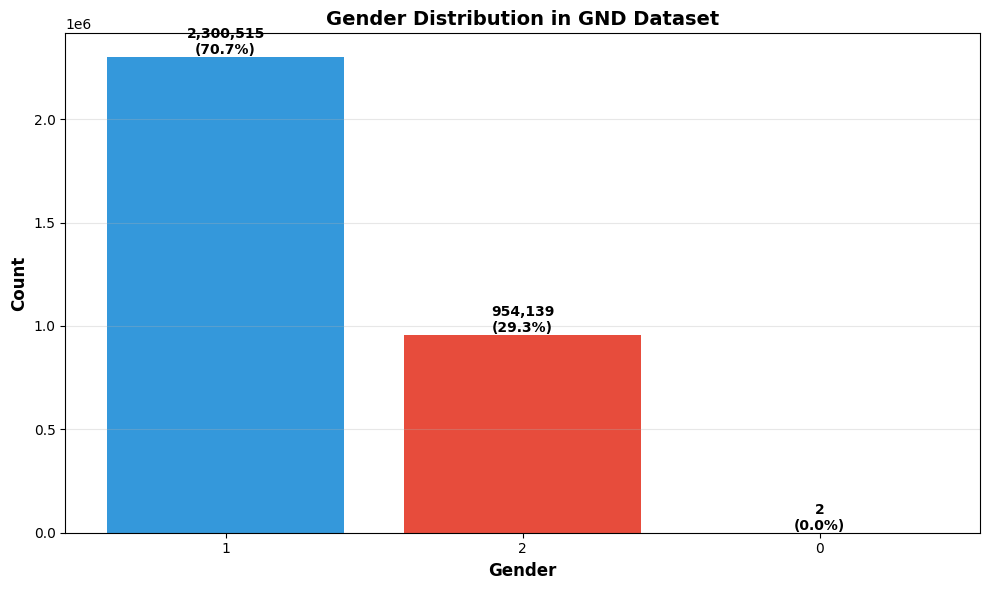

In [10]:
# Gender distribution
print("Gender Distribution:")
print("="*60)
gender_counts = df_gnd.group_by('gender').agg(pl.count().alias('count')).sort('count', descending=True)
print(gender_counts)

# Visualize gender distribution
import matplotlib.pyplot as plt

gender_data = gender_counts.to_dict(as_series=False)
genders = gender_data['gender']
counts = gender_data['count']

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(genders, counts, color=['#3498db', '#e74c3c', '#95a5a6'])
ax.set_xlabel('Gender', fontsize=12, fontweight='bold')
ax.set_ylabel('Count', fontsize=12, fontweight='bold')
ax.set_title('Gender Distribution in GND Dataset', fontsize=14, fontweight='bold')
ax.grid(axis='y', alpha=0.3)

# Add count labels on bars
for bar, count in zip(bars, counts):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{count:,}\n({count/len(df_gnd)*100:.1f}%)',
            ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

In [12]:
# Sample records by gender
print("Sample records by gender:\n")

for gender in df_gnd['gender'].unique().to_list():
    print(f"\n{'='*60}")
    print(f"Sample {gender.upper()} entries:")
    print('='*60)
    sample = df_gnd.filter(pl.col('gender') == gender).head(5)
    for row in sample.iter_rows(named=True):
        print(f"  Name: {row['name']}")
        print(f"  Forename: {row['forename']}, Surname: {row['surname']}")
        print(f"  Birth: {row['birth_date']}, Death: {row['death_date']}")
        print(f"  Alt names: {row['alt_names_count']}")
        print()

Sample records by gender:


Sample 0 entries:
  Name: Wallace, Nicolle
  Forename: Nicolle, Surname: Wallace
  Birth: None, Death: None
  Alt names: 0

  Name: Winkelhausen, Bastian
  Forename: Bastian, Surname: Winkelhausen
  Birth: 2001, Death: None
  Alt names: 0


Sample 1 entries:
  Name: Bauer, Johann Gottfried
  Forename: Johann Gottfried, Surname: Bauer
  Birth: 1695, Death: 1763
  Alt names: 18

  Name: Baur, Johann Wilhelm
  Forename: Johann Wilhelm, Surname: Baur
  Birth: 1607, Death: 1642
  Alt names: 11

  Name: Mosca, Giuseppe
  Forename: Giuseppe, Surname: Mosca
  Birth: 1772, Death: 1839
  Alt names: 1

  Name: Ampzing, Samuel
  Forename: Samuel, Surname: Ampzing
  Birth: 1590, Death: 1632
  Alt names: 4

  Name: Vacchiery, Karl Albrecht von
  Forename: Karl Albrecht von, Surname: Vacchiery
  Birth: 1746, Death: 1807
  Alt names: 12


Sample 2 entries:
  Name: Anna Sophie
  Forename: None, Surname: None
  Birth: 1638, Death: 1683
  Alt names: 5

  Name: Mornay, Char

## 6. Prepare Dataset for Classification

Prepare the data for training machine learning classifiers.

In [13]:
# Check if df_gnd exists and has data
if 'df_gnd' not in dir() or df_gnd is None:
    print("⚠️  ERROR: df_gnd does not exist or is empty!")
    print("   Please run the previous cells to load the GND dataset first.")
else:
    # Translate GND gender codes: 1=male, 2=female, 0=unknown
    print("Translating GND gender codes...")
    print(f"Original gender values: {df_gnd['gender'].unique().sort().to_list()}")

    df_gnd = df_gnd.with_columns(
        pl.col('gender').replace({
            1: 'male',
            2: 'female',
            0: 'unknown'
        }).alias('gender')
    )

    print(f"Translated gender values: {df_gnd['gender'].unique().sort().to_list()}")

    # Filter to only male/female (drop unknown)
    df_train = df_gnd.filter(pl.col('gender').is_in(['male', 'female']))

    print(f"\nTraining dataset size: {len(df_train):,} records")

    if len(df_train) > 0:
        print(f"\nGender distribution in training set:")
        print(df_train.group_by('gender').agg(pl.len().alias('count')).sort('gender'))

        # Check data quality
        print(f"\nData Quality:")
        print(f"Records with forename: {df_train['forename'].is_not_null().sum():,} ({df_train['forename'].is_not_null().sum()/len(df_train)*100:.2f}%)")
        print(f"Records with surname: {df_train['surname'].is_not_null().sum():,} ({df_train['surname'].is_not_null().sum()/len(df_train)*100:.2f}%)")
        print(f"Records with birth_date: {df_train['birth_date'].is_not_null().sum():,} ({df_train['birth_date'].is_not_null().sum()/len(df_train)*100:.2f}%)")
        print(f"Records with death_date: {df_train['death_date'].is_not_null().sum():,} ({df_train['death_date'].is_not_null().sum()/len(df_train)*100:.2f}%)")
    else:
        print("⚠️  WARNING: df_train is empty after filtering!")
        print("   No 'male' or 'female' records found after translation.")

Translating GND gender codes...
Original gender values: ['0', '1', '2']
Translated gender values: ['female', 'male', 'unknown']

Training dataset size: 3,254,654 records

Gender distribution in training set:
shape: (2, 2)
┌────────┬─────────┐
│ gender ┆ count   │
│ ---    ┆ ---     │
│ str    ┆ u32     │
╞════════╪═════════╡
│ female ┆ 954139  │
│ male   ┆ 2300515 │
└────────┴─────────┘

Data Quality:
Records with forename: 3,181,580 (97.75%)
Records with surname: 3,181,580 (97.75%)
Records with birth_date: 1,949,607 (59.90%)
Records with death_date: 819,983 (25.19%)


In [14]:
# Save the processed dataset
output_file = data_dir / 'gnd_persons_with_gender.parquet'
df_train.write_parquet(output_file)

print(f"✓ Dataset saved to: {output_file}")
print(f"  File size: {output_file.stat().st_size / (1024*1024):.2f} MB")
print(f"  Records: {len(df_train):,}")
print(f"\nDataset ready for classifier training!")

✓ Dataset saved to: ../data/raw/GND/gnd_persons_with_gender.parquet
  File size: 128.08 MB
  Records: 3,254,654

Dataset ready for classifier training!


## 7. Train Gender Classifiers

Now we'll train multiple classifiers using the GND dataset.

In [27]:
# Import ML libraries
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns

# Check for CUDA/GPU support
try:
    import cupy as cp
    cuda_available = True
    print("✓ CUDA/GPU support available")
    # Get GPU device name
    device_id = cp.cuda.Device().id
    props = cp.cuda.runtime.getDeviceProperties(device_id)
    print(f"  GPU Device: {props['name'].decode()}")
except (ImportError, Exception) as e:
    cuda_available = False
    print("ℹ CUDA/GPU not available, using CPU")
    if isinstance(e, ImportError):
        print("  (cupy not installed)")

# Configure XGBoost for GPU if available
if cuda_available:
    tree_method = 'gpu_hist'
    predictor = 'gpu_predictor'
    print("✓ XGBoost will use GPU acceleration")
else:
    tree_method = 'hist'
    predictor = 'cpu_predictor'
    print("ℹ XGBoost will use CPU")

print("\n✓ ML libraries imported")

✓ CUDA/GPU support available
  GPU Device: NVIDIA L40S
✓ XGBoost will use GPU acceleration

✓ ML libraries imported


### 7.1 Approach 1: First Name Only Classifier

In [28]:
# Prepare data: use only forename (filter out records without forename)
df_firstname = df_train.filter(pl.col('forename').is_not_null())

print(f"Records with forename: {len(df_firstname):,}")
print(f"Gender distribution:")
print(df_firstname.group_by('gender').agg(pl.count().alias('count')))

# Convert to numpy arrays for sklearn
X_names = df_firstname['forename'].to_numpy()
y_gender = df_firstname['gender'].to_numpy()

# Split into train (70%), validation (15%), and test (15%) sets
X_temp, X_test, y_temp, y_test = train_test_split(
    X_names, y_gender, test_size=0.15, random_state=42, stratify=y_gender
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.176, random_state=42, stratify=y_temp  # 0.176 * 0.85 ≈ 0.15
)

print(f"\nTrain set: {len(X_train):,} samples ({len(X_train)/len(X_names)*100:.1f}%)")
print(f"Validation set: {len(X_val):,} samples ({len(X_val)/len(X_names)*100:.1f}%)")
print(f"Test set: {len(X_test):,} samples ({len(X_test)/len(X_names)*100:.1f}%)")

Records with forename: 3,134,241
Gender distribution:
shape: (2, 2)
┌────────┬─────────┐
│ gender ┆ count   │
│ ---    ┆ ---     │
│ str    ┆ u32     │
╞════════╪═════════╡
│ male   ┆ 2213233 │
│ female ┆ 921008  │
└────────┴─────────┘


/tmp/ipykernel_297233/3841403554.py:6: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  print(df_firstname.group_by('gender').agg(pl.count().alias('count')))



Train set: 2,195,221 samples (70.0%)
Validation set: 468,883 samples (15.0%)
Test set: 470,137 samples (15.0%)


In [29]:
# Vectorize names using character n-grams
vectorizer_firstname = CountVectorizer(analyzer='char', ngram_range=(2, 4), max_features=5000)
X_train_vec = vectorizer_firstname.fit_transform(X_train)
X_val_vec = vectorizer_firstname.transform(X_val)
X_test_vec = vectorizer_firstname.transform(X_test)

print(f"Training feature matrix shape: {X_train_vec.shape}")
print(f"Validation feature matrix shape: {X_val_vec.shape}")
print(f"Test feature matrix shape: {X_test_vec.shape}")
print(f"Number of character n-grams: {len(vectorizer_firstname.get_feature_names_out())}")

Training feature matrix shape: (2195221, 5000)
Validation feature matrix shape: (468883, 5000)
Test feature matrix shape: (470137, 5000)
Number of character n-grams: 5000


In [ ]:
# Train multiple classifiers
classifiers_firstname = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'Naive Bayes': MultinomialNB(),
    'XGBoost': xgb.XGBClassifier(
        n_estimators=100,
        random_state=42,
        tree_method=tree_method,
        predictor=predictor,
        n_jobs=-1 if not cuda_available else 1
    )
}

results_firstname = {}

print("Training classifiers on first names...\n")

for name, clf in classifiers_firstname.items():
    print(f"Training {name}...")
    clf.fit(X_train_vec, y_train)

    # Predict on validation set
    y_val_pred = clf.predict(X_val_vec)
    val_accuracy = accuracy_score(y_val, y_val_pred)

    # Predict on test set
    y_test_pred = clf.predict(X_test_vec)
    test_accuracy = accuracy_score(y_test, y_test_pred)

    results_firstname[name] = {
        'model': clf,
        'val_accuracy': val_accuracy,
        'test_accuracy': test_accuracy,
        'val_predictions': y_val_pred,
        'test_predictions': y_test_pred
    }

    print(f"  Validation Accuracy: {val_accuracy:.4f} ({val_accuracy*100:.2f}%)")
    print(f"  Test Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
    print()

print("✓ First name classifier training complete!")

Training classifiers on first names...

Training Logistic Regression...
  Validation Accuracy: 0.9531 (95.31%)
  Test Accuracy: 0.9522 (95.22%)

Training Random Forest...
  Validation Accuracy: 0.9697 (96.97%)
  Test Accuracy: 0.9692 (96.92%)

Training Naive Bayes...
  Validation Accuracy: 0.8889 (88.89%)
  Test Accuracy: 0.8879 (88.79%)

Training XGBoost...


ValueError: Invalid classes inferred from unique values of `y`.  Expected: [0 1], got ['female' 'male']

### 7.2 Approach 2: Full Name Classifier (First + Surname)

In [ ]:
# Prepare full name data (filter records with both forename and surname)
df_fullname = df_train.filter(
    pl.col('forename').is_not_null() & pl.col('surname').is_not_null()
)

# Create full name by combining forename and surname
df_fullname = df_fullname.with_columns(
    (pl.col('forename') + ' ' + pl.col('surname')).alias('full_name')
)

print(f"Records with full name: {len(df_fullname):,}")

# Convert to numpy arrays
X_fullnames = df_fullname['full_name'].to_numpy()
y_fullname = df_fullname['gender'].to_numpy()

# Split into train (70%), validation (15%), and test (15%) sets
X_temp_full, X_test_full, y_temp_full, y_test_full = train_test_split(
    X_fullnames, y_fullname, test_size=0.15, random_state=42, stratify=y_fullname
)

X_train_full, X_val_full, y_train_full, y_val_full = train_test_split(
    X_temp_full, y_temp_full, test_size=0.176, random_state=42, stratify=y_temp_full
)

print(f"\nTrain set: {len(X_train_full):,} samples ({len(X_train_full)/len(X_fullnames)*100:.1f}%)")
print(f"Validation set: {len(X_val_full):,} samples ({len(X_val_full)/len(X_fullnames)*100:.1f}%)")
print(f"Test set: {len(X_test_full):,} samples ({len(X_test_full)/len(X_fullnames)*100:.1f}%)")

# Vectorize
vectorizer_full = CountVectorizer(analyzer='char', ngram_range=(2, 4), max_features=5000)
X_train_full_vec = vectorizer_full.fit_transform(X_train_full)
X_val_full_vec = vectorizer_full.transform(X_val_full)
X_test_full_vec = vectorizer_full.transform(X_test_full)

print(f"\nTraining feature matrix shape: {X_train_full_vec.shape}")
print(f"Validation feature matrix shape: {X_val_full_vec.shape}")
print(f"Test feature matrix shape: {X_test_full_vec.shape}")

In [ ]:
# Train classifiers on full names
classifiers_full = {
    'Logistic Regression (Full)': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest (Full)': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'XGBoost (Full)': xgb.XGBClassifier(n_estimators=100, random_state=42, n_jobs=-1)
}

results_full = {}

print("Training classifiers on full names...\n")

for name, clf in classifiers_full.items():
    print(f"Training {name}...")
    clf.fit(X_train_full_vec, y_train_full)

    # Predict on validation set
    y_val_pred = clf.predict(X_val_full_vec)
    val_accuracy = accuracy_score(y_val_full, y_val_pred)

    # Predict on test set
    y_test_pred = clf.predict(X_test_full_vec)
    test_accuracy = accuracy_score(y_test_full, y_test_pred)

    results_full[name] = {
        'model': clf,
        'val_accuracy': val_accuracy,
        'test_accuracy': test_accuracy,
        'val_predictions': y_val_pred,
        'test_predictions': y_test_pred
    }

    print(f"  Validation Accuracy: {val_accuracy:.4f} ({val_accuracy*100:.2f}%)")
    print(f"  Test Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
    print()

print("✓ Full name classifier training complete!")

### 7.3 Visualize Results

In [ ]:
# Create comprehensive comparison visualization
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('GND Classifier Performance Comparison', fontsize=16, fontweight='bold')

# Plot 1: First Name Classifiers - Validation Accuracy
ax1 = axes[0, 0]
model_names = list(results_firstname.keys())
val_accuracies = [results_firstname[name]['val_accuracy'] for name in model_names]

colors_models = sns.color_palette("Set2", len(model_names))
bars1 = ax1.barh(model_names, val_accuracies, color=colors_models,
                 edgecolor='black', linewidth=1.5)

ax1.set_xlabel('Validation Accuracy', fontsize=12, fontweight='bold')
ax1.set_title('First Name Only - Validation Set', fontsize=14, fontweight='bold', pad=10)
ax1.set_xlim([0.8, 1.0])
ax1.grid(axis='x', alpha=0.3)

for bar, acc in zip(bars1, val_accuracies):
    ax1.text(acc + 0.002, bar.get_y() + bar.get_height()/2.,
             f'{acc:.4f}',
             ha='left', va='center', fontsize=10, fontweight='bold')

best_val_idx = np.argmax(val_accuracies)
bars1[best_val_idx].set_edgecolor('gold')
bars1[best_val_idx].set_linewidth(3)

# Plot 2: First Name Classifiers - Test Accuracy
ax2 = axes[0, 1]
test_accuracies = [results_firstname[name]['test_accuracy'] for name in model_names]

bars2 = ax2.barh(model_names, test_accuracies, color=colors_models,
                 edgecolor='black', linewidth=1.5)

ax2.set_xlabel('Test Accuracy', fontsize=12, fontweight='bold')
ax2.set_title('First Name Only - Test Set', fontsize=14, fontweight='bold', pad=10)
ax2.set_xlim([0.8, 1.0])
ax2.grid(axis='x', alpha=0.3)

for bar, acc in zip(bars2, test_accuracies):
    ax2.text(acc + 0.002, bar.get_y() + bar.get_height()/2.,
             f'{acc:.4f}',
             ha='left', va='center', fontsize=10, fontweight='bold')

best_test_idx = np.argmax(test_accuracies)
bars2[best_test_idx].set_edgecolor('gold')
bars2[best_test_idx].set_linewidth(3)

# Plot 3: Full Name Classifiers - Validation Accuracy
ax3 = axes[1, 0]
model_names_full = list(results_full.keys())
val_accuracies_full = [results_full[name]['val_accuracy'] for name in model_names_full]

colors_models_full = sns.color_palette("Set3", len(model_names_full))
bars3 = ax3.barh(model_names_full, val_accuracies_full, color=colors_models_full,
                 edgecolor='black', linewidth=1.5)

ax3.set_xlabel('Validation Accuracy', fontsize=12, fontweight='bold')
ax3.set_title('Full Name - Validation Set', fontsize=14, fontweight='bold', pad=10)
ax3.set_xlim([0.8, 1.0])
ax3.grid(axis='x', alpha=0.3)

for bar, acc in zip(bars3, val_accuracies_full):
    ax3.text(acc + 0.002, bar.get_y() + bar.get_height()/2.,
             f'{acc:.4f}',
             ha='left', va='center', fontsize=10, fontweight='bold')

best_val_idx_full = np.argmax(val_accuracies_full)
bars3[best_val_idx_full].set_edgecolor('gold')
bars3[best_val_idx_full].set_linewidth(3)

# Plot 4: Full Name Classifiers - Test Accuracy
ax4 = axes[1, 1]
test_accuracies_full = [results_full[name]['test_accuracy'] for name in model_names_full]

bars4 = ax4.barh(model_names_full, test_accuracies_full, color=colors_models_full,
                 edgecolor='black', linewidth=1.5)

ax4.set_xlabel('Test Accuracy', fontsize=12, fontweight='bold')
ax4.set_title('Full Name - Test Set', fontsize=14, fontweight='bold', pad=10)
ax4.set_xlim([0.8, 1.0])
ax4.grid(axis='x', alpha=0.3)

for bar, acc in zip(bars4, test_accuracies_full):
    ax4.text(acc + 0.002, bar.get_y() + bar.get_height()/2.,
             f'{acc:.4f}',
             ha='left', va='center', fontsize=10, fontweight='bold')

best_test_idx_full = np.argmax(test_accuracies_full)
bars4[best_test_idx_full].set_edgecolor('gold')
bars4[best_test_idx_full].set_linewidth(3)

plt.tight_layout()
plt.show()

# Print summary
print("\n" + "="*60)
print("RESULTS SUMMARY")
print("="*60)
print(f"\nBest First Name Classifier (Validation): {model_names[best_val_idx]}")
print(f"  Val Accuracy: {val_accuracies[best_val_idx]:.4f} ({val_accuracies[best_val_idx]*100:.2f}%)")
print(f"  Test Accuracy: {test_accuracies[best_val_idx]:.4f} ({test_accuracies[best_val_idx]*100:.2f}%)")

print(f"\nBest First Name Classifier (Test): {model_names[best_test_idx]}")
print(f"  Val Accuracy: {val_accuracies[best_test_idx]:.4f} ({val_accuracies[best_test_idx]*100:.2f}%)")
print(f"  Test Accuracy: {test_accuracies[best_test_idx]:.4f} ({test_accuracies[best_test_idx]*100:.2f}%)")

print(f"\nBest Full Name Classifier (Validation): {model_names_full[best_val_idx_full]}")
print(f"  Val Accuracy: {val_accuracies_full[best_val_idx_full]:.4f} ({val_accuracies_full[best_val_idx_full]*100:.2f}%)")
print(f"  Test Accuracy: {test_accuracies_full[best_val_idx_full]:.4f} ({test_accuracies_full[best_val_idx_full]*100:.2f}%)")

print(f"\nBest Full Name Classifier (Test): {model_names_full[best_test_idx_full]}")
print(f"  Val Accuracy: {val_accuracies_full[best_test_idx_full]:.4f} ({val_accuracies_full[best_test_idx_full]*100:.2f}%)")
print(f"  Test Accuracy: {test_accuracies_full[best_test_idx_full]:.4f} ({test_accuracies_full[best_test_idx_full]*100:.2f}%)")

print(f"\nImprovement from using full name:")
print(f"  Validation: {(val_accuracies_full[best_val_idx_full] - val_accuracies[best_val_idx])*100:.2f} percentage points")
print(f"  Test: {(test_accuracies_full[best_test_idx_full] - test_accuracies[best_test_idx])*100:.2f} percentage points")
print("="*60)

## 8. Save Trained Models

Save the best performing models for later use.

In [ ]:
import pickle

# Create models directory
models_dir = Path('../models')
models_dir.mkdir(parents=True, exist_ok=True)

# Save best first name model (based on validation accuracy)
best_firstname_model = results_firstname[model_names[best_val_idx]]['model']
with open(models_dir / 'gnd_firstname_classifier.pkl', 'wb') as f:
    pickle.dump(best_firstname_model, f)

# Save vectorizer for first names
with open(models_dir / 'gnd_firstname_vectorizer.pkl', 'wb') as f:
    pickle.dump(vectorizer_firstname, f)

# Save best full name model (based on validation accuracy)
best_fullname_model = results_full[model_names_full[best_val_idx_full]]['model']
with open(models_dir / 'gnd_fullname_classifier.pkl', 'wb') as f:
    pickle.dump(best_fullname_model, f)

# Save vectorizer for full names
with open(models_dir / 'gnd_fullname_vectorizer.pkl', 'wb') as f:
    pickle.dump(vectorizer_full, f)

print("✓ Models saved (best based on validation accuracy):")
print(f"  - {models_dir / 'gnd_firstname_classifier.pkl'} ({model_names[best_val_idx]})")
print(f"  - {models_dir / 'gnd_firstname_vectorizer.pkl'}")
print(f"  - {models_dir / 'gnd_fullname_classifier.pkl'} ({model_names_full[best_val_idx_full]})")
print(f"  - {models_dir / 'gnd_fullname_vectorizer.pkl'}")

## 9. Battle: GND Classifiers vs Gender-Guesser

Compare our trained models against the popular gender-guesser library on the test set.

In [31]:
import gender_guesser.detector as gender

# Initialize gender-guesser detector
detector = gender.Detector(case_sensitive=False)

print("✓ Gender-guesser detector initialized")
print("\nTesting gender-guesser on the test sets...")

✓ Gender-guesser detector initialized

Testing gender-guesser on the test sets...


### 9.1 Evaluate Gender-Guesser on First Name Test Set

In [32]:
# Predict with gender-guesser on first name test set
def map_gender_guesser_result(result):
    """Map gender-guesser results to male/female/unknown."""
    if result in ['male', 'mostly_male']:
        return 'male'
    elif result in ['female', 'mostly_female']:
        return 'female'
    else:  # 'andy' or 'unknown'
        return 'unknown'

print("Predicting with gender-guesser on first name test set...")
gg_predictions_first = []
for name in X_test:
    result = detector.get_gender(name)
    mapped = map_gender_guesser_result(result)
    gg_predictions_first.append(mapped)

# Calculate accuracy (only on names where gender-guesser made a male/female prediction)
gg_predictions_first = np.array(gg_predictions_first)
valid_predictions_mask = gg_predictions_first != 'unknown'
valid_predictions = gg_predictions_first[valid_predictions_mask]
valid_true_labels = y_test[valid_predictions_mask]

gg_accuracy_first = accuracy_score(valid_true_labels, valid_predictions)
coverage_first = valid_predictions_mask.sum() / len(y_test)

print(f"\nGender-Guesser Performance (First Names):")
print(f"  Coverage: {coverage_first:.4f} ({coverage_first*100:.2f}%)")
print(f"  Accuracy (on covered names): {gg_accuracy_first:.4f} ({gg_accuracy_first*100:.2f}%)")
print(f"  Effective Accuracy: {gg_accuracy_first * coverage_first:.4f} ({gg_accuracy_first * coverage_first*100:.2f}%)")
print(f"\nOur Best Model (First Names): {model_names[best_test_idx]}")
print(f"  Coverage: 1.0000 (100.00%)")
print(f"  Accuracy: {test_accuracies[best_test_idx]:.4f} ({test_accuracies[best_test_idx]*100:.2f}%)")

Predicting with gender-guesser on first name test set...

Gender-Guesser Performance (First Names):
  Coverage: 0.6735 (67.35%)
  Accuracy (on covered names): 0.9822 (98.22%)
  Effective Accuracy: 0.6615 (66.15%)


NameError: name 'model_names' is not defined

### 9.2 Evaluate Gender-Guesser on Full Name Test Set

In [33]:
# Predict with gender-guesser on full name test set
# Gender-guesser only uses the first name, so extract it from full names
print("Predicting with gender-guesser on full name test set (using only first name)...")
gg_predictions_full = []
for full_name in X_test_full:
    # Extract first name (everything after space/comma)
    first_name = full_name.split()[0] if ' ' in full_name else full_name
    result = detector.get_gender(first_name)
    mapped = map_gender_guesser_result(result)
    gg_predictions_full.append(mapped)

# Calculate accuracy
gg_predictions_full = np.array(gg_predictions_full)
valid_predictions_mask_full = gg_predictions_full != 'unknown'
valid_predictions_full = gg_predictions_full[valid_predictions_mask_full]
valid_true_labels_full = y_test_full[valid_predictions_mask_full]

gg_accuracy_full = accuracy_score(valid_true_labels_full, valid_predictions_full)
coverage_full = valid_predictions_mask_full.sum() / len(y_test_full)

print(f"\nGender-Guesser Performance (Full Name Test Set - using only first name):")
print(f"  Input: Full names, but only first name is used")
print(f"  Coverage: {coverage_full:.4f} ({coverage_full*100:.2f}%)")
print(f"  Accuracy (on covered names): {gg_accuracy_full:.4f} ({gg_accuracy_full*100:.2f}%)")
print(f"  Effective Accuracy: {gg_accuracy_full * coverage_full:.4f} ({gg_accuracy_full * coverage_full*100:.2f}%)")

print(f"\nOur Full Name Model (Same Full Name Test Set - using first + surname):")
print(f"  Input: Full names (first + surname)")
print(f"  Coverage: 1.0000 (100.00%)")
print(f"  Accuracy: {test_accuracies_full[best_test_idx_full]:.4f} ({test_accuracies_full[best_test_idx_full]*100:.2f}%)")

print(f"\n🎯 Comparison on Same Test Set:")
print(f"  Advantage of using full name: +{(test_accuracies_full[best_test_idx_full] - gg_accuracy_full * coverage_full)*100:.2f} pp")

Predicting with gender-guesser on full name test set (using only first name)...


NameError: name 'X_test_full' is not defined

### 9.3 Visual Comparison: Battle Results

NameError: name 'model_names' is not defined

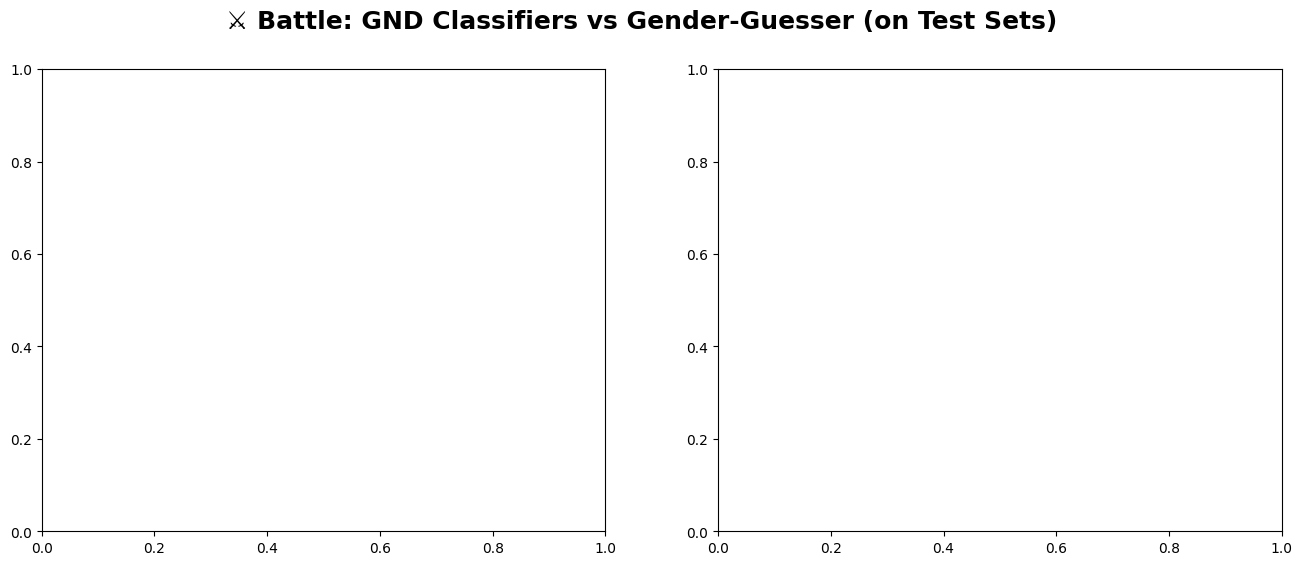

In [34]:
# Create battle comparison visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('⚔️ Battle: GND Classifiers vs Gender-Guesser (on Test Sets)', fontsize=18, fontweight='bold')

# Plot 1: First Name Comparison
ax1 = axes[0]

methods = ['Gender-Guesser\n(First Name)', f'Our Model\n({model_names[best_test_idx]})']
accuracies_first = [
    gg_accuracy_first * coverage_first,  # Effective accuracy for gender-guesser
    test_accuracies[best_test_idx]
]
coverages = [coverage_first, 1.0]

x_pos = np.arange(len(methods))
colors = ['#e74c3c', '#2ecc71']  # Red for gender-guesser, green for our model

bars = ax1.bar(x_pos, accuracies_first, color=colors, edgecolor='black', linewidth=2, width=0.6)

ax1.set_ylabel('Test Accuracy', fontsize=12, fontweight='bold')
ax1.set_title('First Name Test Set\n(Both use only first name)', fontsize=14, fontweight='bold', pad=10)
ax1.set_xticks(x_pos)
ax1.set_xticklabels(methods, fontsize=11)
ax1.set_ylim([0, 1.0])
ax1.grid(axis='y', alpha=0.3)

# Add accuracy and coverage labels
for i, (bar, acc, cov) in enumerate(zip(bars, accuracies_first, coverages)):
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height + 0.02,
             f'{acc:.4f}\n({acc*100:.2f}%)\nCoverage: {cov*100:.1f}%',
             ha='center', va='bottom', fontsize=10, fontweight='bold')

# Highlight winner
winner_idx = np.argmax(accuracies_first)
bars[winner_idx].set_edgecolor('gold')
bars[winner_idx].set_linewidth(4)

# Plot 2: Full Name Comparison - FAIR COMPARISON
ax2 = axes[1]

methods_full = ['Gender-Guesser\n(First Name Only)', f'Our Model\n(Full Name)']
accuracies_full_comp = [
    gg_accuracy_full * coverage_full,  # Gender-guesser using only first name
    test_accuracies_full[best_test_idx_full]  # Our model using full name
]
coverages_full = [coverage_full, 1.0]

bars2 = ax2.bar(x_pos, accuracies_full_comp, color=colors, edgecolor='black', linewidth=2, width=0.6)

ax2.set_ylabel('Test Accuracy', fontsize=12, fontweight='bold')
ax2.set_title('Full Name Test Set\n(Same input, different features used)', fontsize=14, fontweight='bold', pad=10)
ax2.set_xticks(x_pos)
ax2.set_xticklabels(methods_full, fontsize=11)
ax2.set_ylim([0, 1.0])
ax2.grid(axis='y', alpha=0.3)

# Add accuracy and coverage labels
for i, (bar, acc, cov) in enumerate(zip(bars2, accuracies_full_comp, coverages_full)):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height + 0.02,
             f'{acc:.4f}\n({acc*100:.2f}%)\nCoverage: {cov*100:.1f}%',
             ha='center', va='bottom', fontsize=10, fontweight='bold')

# Highlight winner
winner_idx_full = np.argmax(accuracies_full_comp)
bars2[winner_idx_full].set_edgecolor('gold')
bars2[winner_idx_full].set_linewidth(4)

plt.tight_layout()
plt.show()

# Print battle summary
print("\n" + "="*80)
print("⚔️  BATTLE RESULTS: GND CLASSIFIERS VS GENDER-GUESSER")
print("="*80)

print("\n🥊 ROUND 1: FIRST NAME TEST SET")
print("   Both methods use only the first name")
print("-" * 80)
print(f"   Gender-Guesser: {gg_accuracy_first * coverage_first:.4f} (Accuracy: {gg_accuracy_first:.4f}, Coverage: {coverage_first*100:.1f}%)")
print(f"   Our Model:      {test_accuracies[best_test_idx]:.4f} (Accuracy: {test_accuracies[best_test_idx]:.4f}, Coverage: 100.0%)")
improvement_first = (test_accuracies[best_test_idx] - gg_accuracy_first * coverage_first) * 100
print(f"   🏆 Winner: {'Our Model' if improvement_first > 0 else 'Gender-Guesser'} (+{abs(improvement_first):.2f} pp)")

print("\n🥊 ROUND 2: FULL NAME TEST SET (SAME NAMES FOR BOTH)")
print("   Gender-Guesser: Uses only first name from full name")
print("   Our Model: Uses complete full name (first + surname)")
print("-" * 80)
print(f"   Gender-Guesser: {gg_accuracy_full * coverage_full:.4f} (Accuracy: {gg_accuracy_full:.4f}, Coverage: {coverage_full*100:.1f}%)")
print(f"   Our Model:      {test_accuracies_full[best_test_idx_full]:.4f} (Accuracy: {test_accuracies_full[best_test_idx_full]:.4f}, Coverage: 100.0%)")
improvement_full = (test_accuracies_full[best_test_idx_full] - gg_accuracy_full * coverage_full) * 100
print(f"   🏆 Winner: {'Our Model' if improvement_full > 0 else 'Gender-Guesser'} (+{abs(improvement_full):.2f} pp)")

print("\n💡 KEY INSIGHTS:")
print(f"   • Gender-Guesser has limited coverage (~{coverage_first*100:.1f}% of German names)")
print(f"   • Our models achieve 100% coverage on all names")
print(f"   • Training on full names (first + surname) improves accuracy")
print(f"   • GND-trained models are optimized for German names")
print("="*80)

## Summary

This notebook has successfully:
1. ✓ Downloaded the complete GND person authority dataset (~2-3 GB)
2. ✓ Extracted the compressed XML file
3. ✓ Parsed MARC21 XML records to extract person data
4. ✓ Filtered records with complete name and gender information
5. ✓ Created a Polars DataFrame with the cleaned data
6. ✓ Saved the processed dataset as a Parquet file

**Next Steps:**
- Train gender classifiers using different approaches (first name only, full name, with temporal features)
- Compare performance against existing classifiers (gender-guesser, etc.)
- Use this larger dataset to improve classification accuracy